# 1.Import Libraries

In [24]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split , cross_val_score , StratifiedKFold
from sklearn.metrics import roc_auc_score

from sklearn.linear_model import LinearRegression , Ridge
from sklearn.preprocessing import PolynomialFeatures

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder

import pickle


# Read Data and configration

In [2]:
df = pd.read_csv("insurance.csv")
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [4]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [5]:
# Missing value
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

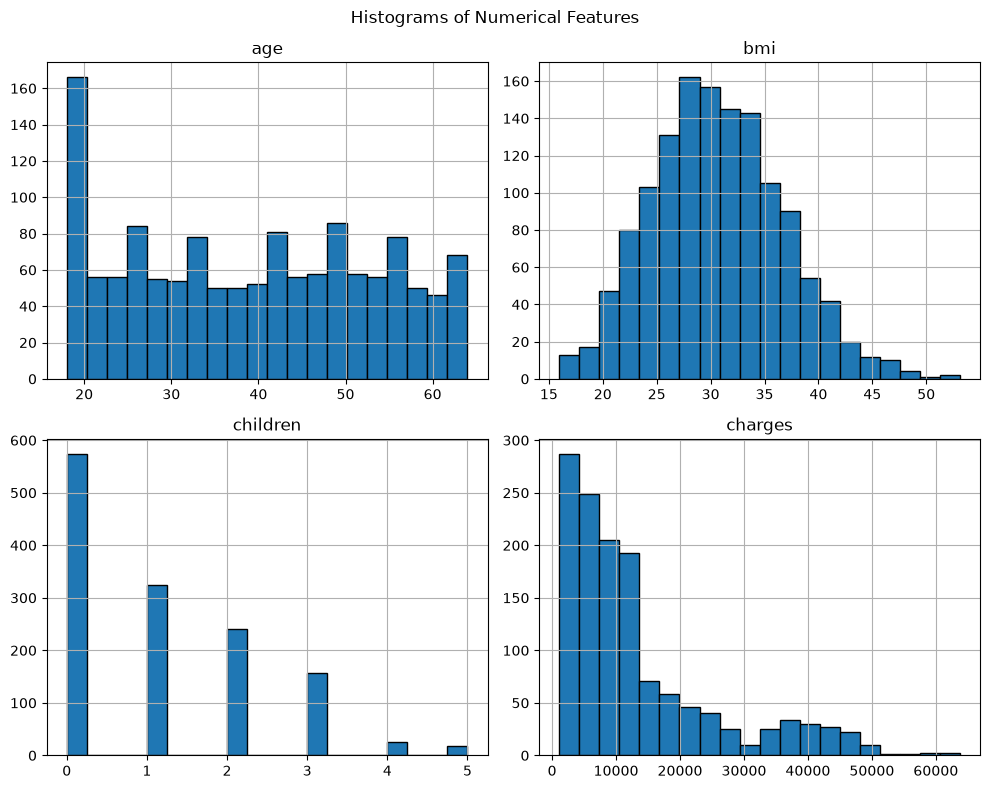

In [6]:
# Distribution of Numerical Feature
df.hist(figsize=(10, 8), bins=20, edgecolor='black')

plt.suptitle("Histograms of Numerical Features")
plt.tight_layout()
plt.show()

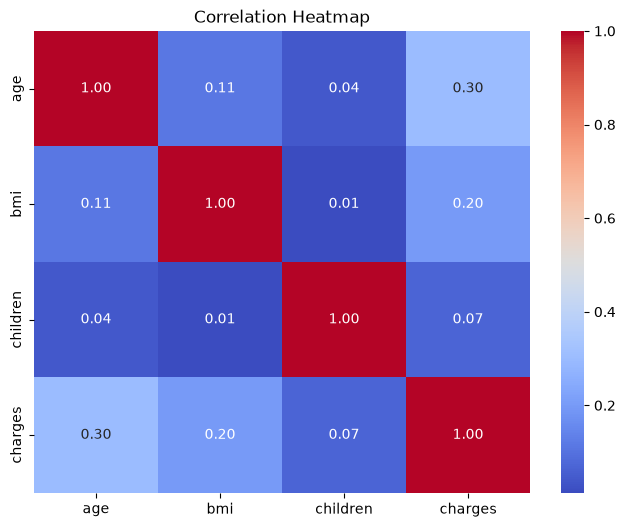

In [7]:
# Correlation Heatmap

plt.figure(figsize=(8, 6))

corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

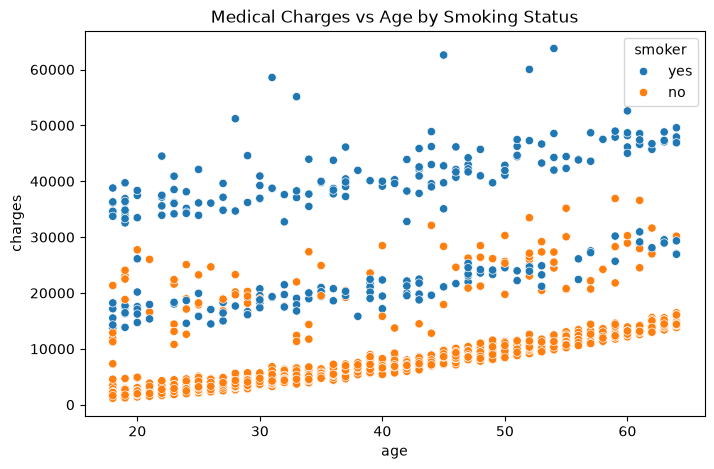

In [8]:
# Smoking Vs Medical charges
plt.figure(figsize=(8, 5))

sns.scatterplot(x='age', y='charges', hue='smoker', data=df)

plt.title("Medical Charges vs Age by Smoking Status")
plt.show()

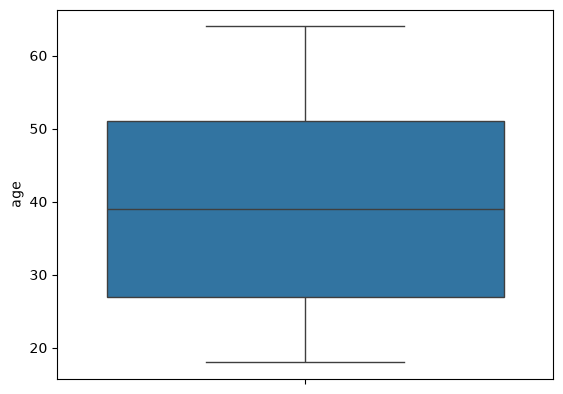

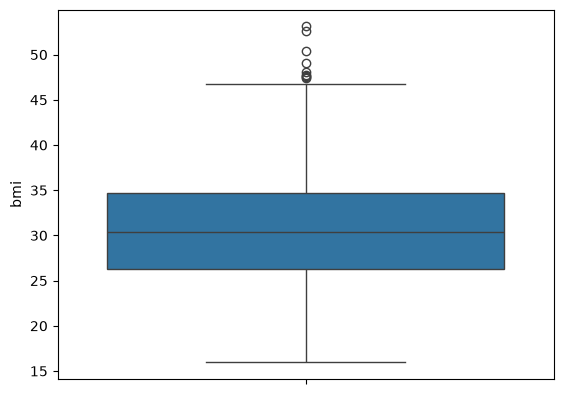

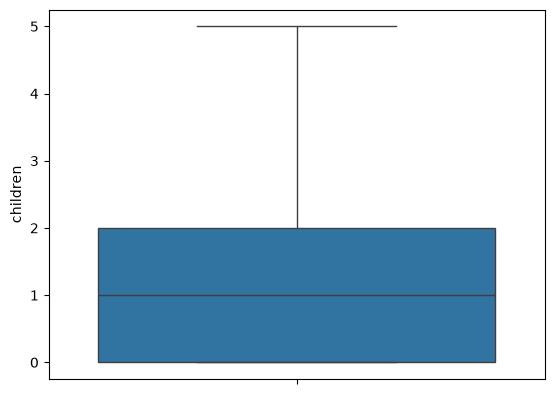

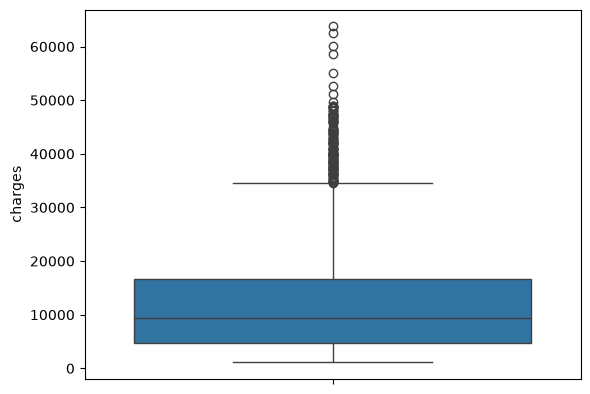

In [9]:
#chick Outliear
num_features = df.select_dtypes(include='number')

for col in num_features.columns:
    plt.Figure()
    sns.boxplot(df[col])
    plt.show()

In [10]:
df.drop_duplicates(inplace=True)

# Split Data for Training , Validate and Testing

In [11]:
X=df.drop("charges", axis=1)
Y=df["charges"]

In [12]:
X_train, X_temp, Y_train, Y_temp = train_test_split(
    X, Y, test_size=0.3, random_state=42
)

X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp, Y_temp, test_size=0.5, random_state=42
)

# Apply StandardScaler and OneHotEncoder

In [13]:
num_cols = ['age', 'bmi', 'children']
cat_cols = ['sex', 'smoker', 'region']

scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train[num_cols])
X_val_num = scaler.transform(X_val[num_cols])
X_test_num = scaler.transform(X_test[num_cols])

In [14]:
encoder = OneHotEncoder(drop='first', sparse_output=False)
X_train_cat = encoder.fit_transform(X_train[cat_cols])
X_val_cat = encoder.transform(X_val[cat_cols])
X_test_cat = encoder.transform(X_test[cat_cols])

In [15]:
# merge the two steps

X_train_processed = np.hstack((X_train_num, X_train_cat))
X_val_processed = np.hstack((X_val_num, X_val_cat))
X_test_processed = np.hstack((X_test_num, X_test_cat))

# Part 1: Linear Regression Model

In [29]:
# Baseline Linear Regression

lr_model = LinearRegression()
lr_model.fit(X_train_processed, Y_train)

Y_val_pred_lr = lr_model.predict(X_val_processed)
val_rmse_lr = np.sqrt(mean_squared_error(Y_val, Y_val_pred_lr))
val_r2_lr = r2_score(Y_val, Y_val_pred_lr)

print(f"Baseline Linear Regression -> \n Val RMSE: {val_rmse_lr:.2f}\n Val R2: {val_r2_lr:.4f}")
print("-" * 55)

Baseline Linear Regression -> 
 Val RMSE: 6316.68
 Val R2: 0.7668
-------------------------------------------------------


In [30]:
# Final Evaluate
Y_pred = lr_model.predict(X_test_processed)

test_mae = mean_absolute_error(Y_test, Y_pred)
test_rmse = np.sqrt(mean_squared_error(Y_test, Y_pred))
test_r2 = r2_score(Y_test, Y_pred)

print("Final Test Set Evaluation:")
print(f"MAE:  {test_mae:.2f}")
print(f"RMSE: {test_rmse:.2f}")
print(f"R2:   {test_r2:.4f}")

Final Test Set Evaluation:
MAE:  4041.91
RMSE: 6162.78
R2:   0.7774


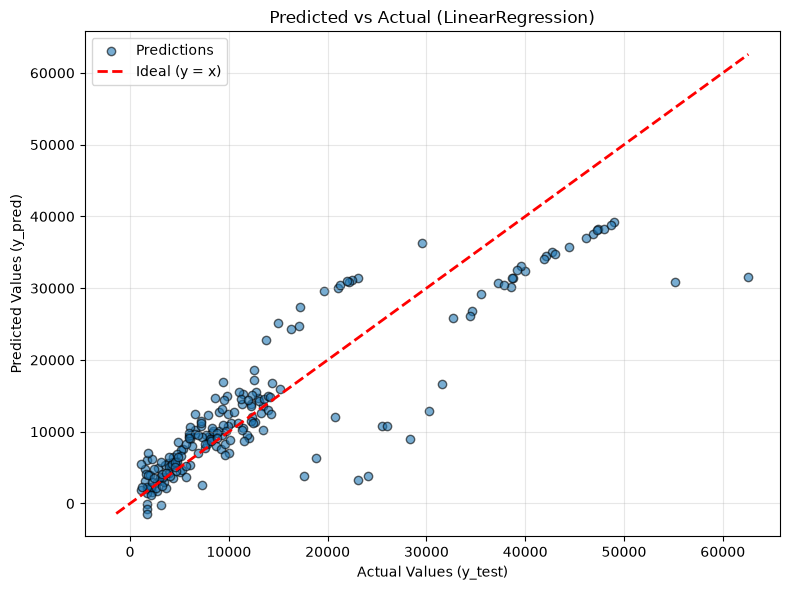

In [31]:
# Predicted vs Actual
plt.figure(figsize=(8, 6))
plt.scatter(Y_test, Y_pred, alpha=0.6, edgecolors='k', label='Predictions')

min_val = min(Y_test.min(), Y_pred.min())
max_val = max(Y_test.max(), Y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal (y = x)')

plt.xlabel('Actual Values (y_test)')
plt.ylabel('Predicted Values (y_pred)')
plt.title(f'Predicted vs Actual (LinearRegression)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Second Experiment: Polynomial Features (Degree 2) + Ridge Tuning

In [32]:

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_processed)
X_val_poly = poly.transform(X_val_processed)
X_test_poly = poly.transform(X_test_processed)

print(f"Original shape: {X_train_processed.shape}")
print(f"Polynomial shape: {X_train_poly.shape}")
print("-" * 55)



Original shape: (935, 8)
Polynomial shape: (935, 44)
-------------------------------------------------------


In [33]:
lr_poly = LinearRegression()
lr_poly.fit(X_train_poly, Y_train)

y_val_pred = lr_poly.predict(X_val_poly)
val_rmse = np.sqrt(mean_squared_error(Y_val, y_val_pred))
val_r2 = r2_score(Y_val, y_val_pred)


In [34]:
#final prediction
y_pred_poly = lr_poly.predict(X_test_poly)

test_mae_poly = mean_absolute_error(Y_test, y_pred_poly)
test_rmse_poly = np.sqrt(mean_squared_error(Y_test, y_pred_poly))
test_r2_poly = r2_score(Y_test, y_pred_poly)

old_r2 = 0.7774
print("Final Test Set Evaluation (Polynomial LinearRegression):")
print(f"MAE:  {test_mae_poly:.2f}")
print(f"RMSE: {test_rmse_poly:.2f}")
print(f"R2:   {test_r2_poly:.4f}  (Old R2: {old_r2:.4f} | Diff: {test_r2_poly - old_r2:+.4f})")

Final Test Set Evaluation (Polynomial LinearRegression):
MAE:  2902.69
RMSE: 5202.20
R2:   0.8414  (Old R2: 0.7774 | Diff: +0.0640)


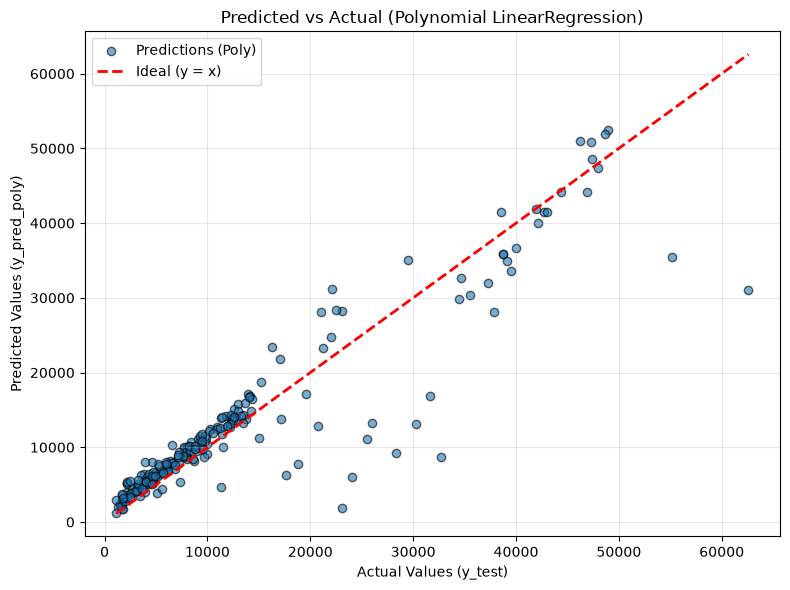

In [35]:
# Predicted vs Actual for polynomial LinearRegression
plt.figure(figsize=(8, 6))
plt.scatter(Y_test, y_pred_poly, alpha=0.6, edgecolors='k', label='Predictions (Poly)')

min_val = min(Y_test.min(), y_pred_poly.min())
max_val = max(Y_test.max(), y_pred_poly.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal (y = x)')

plt.xlabel('Actual Values (y_test)')
plt.ylabel('Predicted Values (y_pred_poly)')
plt.title('Predicted vs Actual (Polynomial LinearRegression)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Part 2: KNN Model